In [1]:
import os
os.environ['JAX_PLATFORM_NAME'] = 'cpu'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

n_threads = "5" 
os.environ["OMP_NUM_THREADS"] = n_threads
os.environ["OPENBLAS_NUM_THREADS"] = n_threads
os.environ["MKL_NUM_THREADS"] = n_threads
os.environ["VECLIB_MAXIMUM_THREADS"] = n_threads
os.environ["NUMEXPR_NUM_THREADS"] = n_threads

import jax
import moscot

import glob
import pandas as pd
import scanpy as sc
import anndata as ad
import scvelo as scv
import cellrank as cr
import numpy as np
import matplotlib.pyplot as plt
import palantir

scv.set_figure_params()

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['savefig.dpi'] = 300

E0910 17:30:08.326777 2581706 cuda_dnn.cc:435] There was an error before creating cudnn handle (35): cudaErrorInsufficientDriver : CUDA driver version is insufficient for CUDA runtime version
E0910 17:30:08.327082 2581706 cuda_dnn.cc:435] There was an error before creating cudnn handle (35): cudaErrorInsufficientDriver : CUDA driver version is insufficient for CUDA runtime version


In [2]:
os.chdir('/data_hdd4/yuseong/cancer_aging/analysis/h.github/Fig2')

### CellRank2

In [3]:
adata = sc.read_h5ad('data/2f_h_j/patient_endo_scvelo.h5ad')
adata

AnnData object with n_obs × n_vars = 2406 × 35155
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'percent.mt', 'RNA_snn_res.1', 'seurat_clusters', 'condition', 'origin', 'CellType', 'barcode', 'EMT', 'ECM', 'SEN_MAYO', 'CELLULAR.RESPONSE.TO.UV', 'RESPONSE.TO.UV', 'EndMT', 'M3', 'umap_1', 'umap_2', 'Patient', 'tissue', 'treatment', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'SAMPLE', 'n_counts', 'velocity_self_transition', 'leiden', 'Endothelial_clusters', 'sub_match'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'Endothelial_clusters_colors', 'condition_colors', 'condition_sizes', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'origin_colors', 'pag

In [4]:
#### velocity kernel

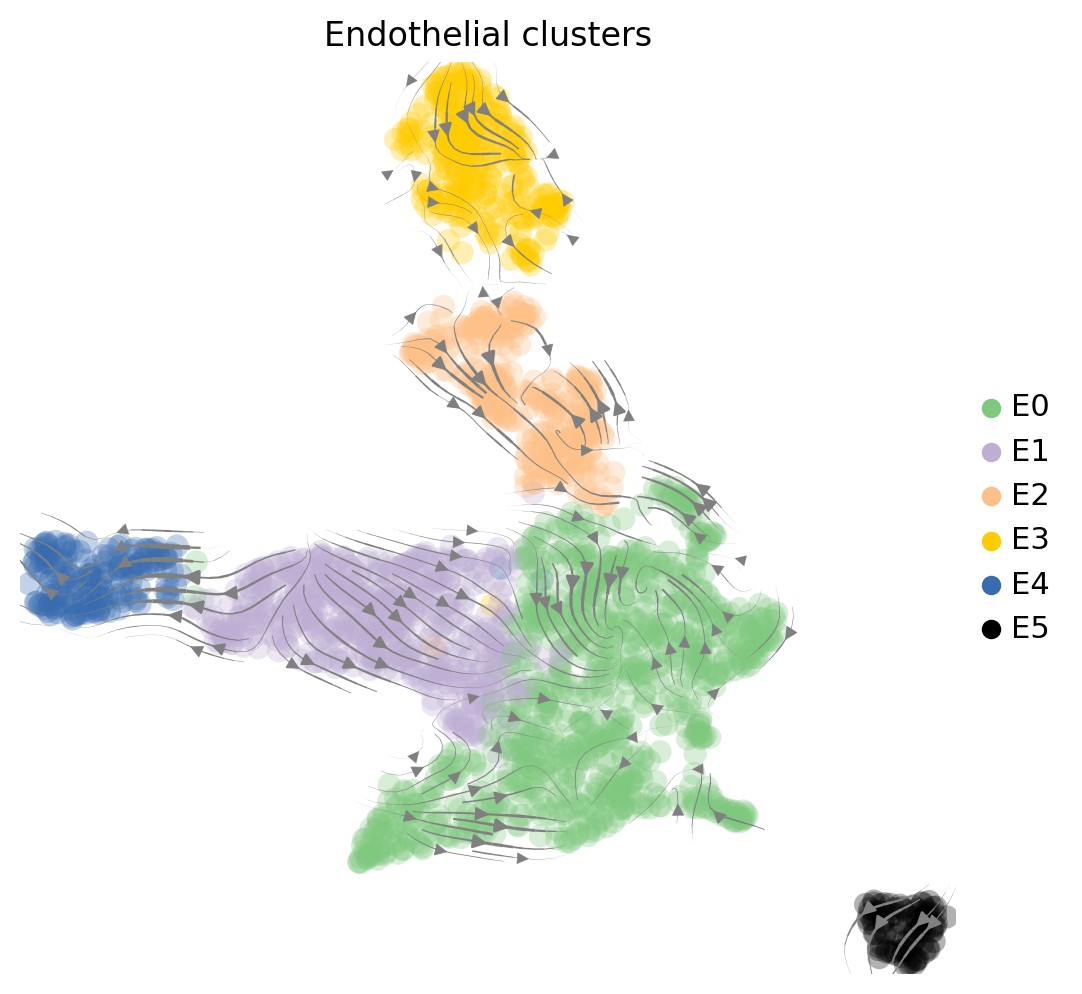

In [5]:
scv.pl.velocity_embedding_stream(adata, basis="umap", color="Endothelial_clusters", density=3,legend_loc = 'right', arrow_color = 'grey', figsize=(6, 6))

In [6]:
vk = cr.kernels.VelocityKernel(adata)

In [7]:
vk.compute_transition_matrix()

  0%|          | 0/2406 [00:00<?, ?cell/s]

  0%|          | 0/2406 [00:00<?, ?cell/s]

VelocityKernel[n=2406, model='deterministic', similarity='correlation', softmax_scale=np.float64(8.848)]

In [8]:
#### experimental time kernel

In [9]:
from moscot.problems.time import TemporalProblem
from cellrank.kernels import RealTimeKernel

In [10]:
adata.obs["day"] = adata.obs["condition"].apply(lambda x : 0 if x == 'Pre' else (1 if x =='On' else 4)).astype(float).astype("category")

# In addition, it's nicer for plotting to have numerical values.
adata.obs["day_numerical"] = adata.obs["day"].astype(float)

In [11]:
adata.obs.condition.unique()

['Pre', 'On', 'Post']
Categories (3, object): ['Pre' < 'On' < 'Post']

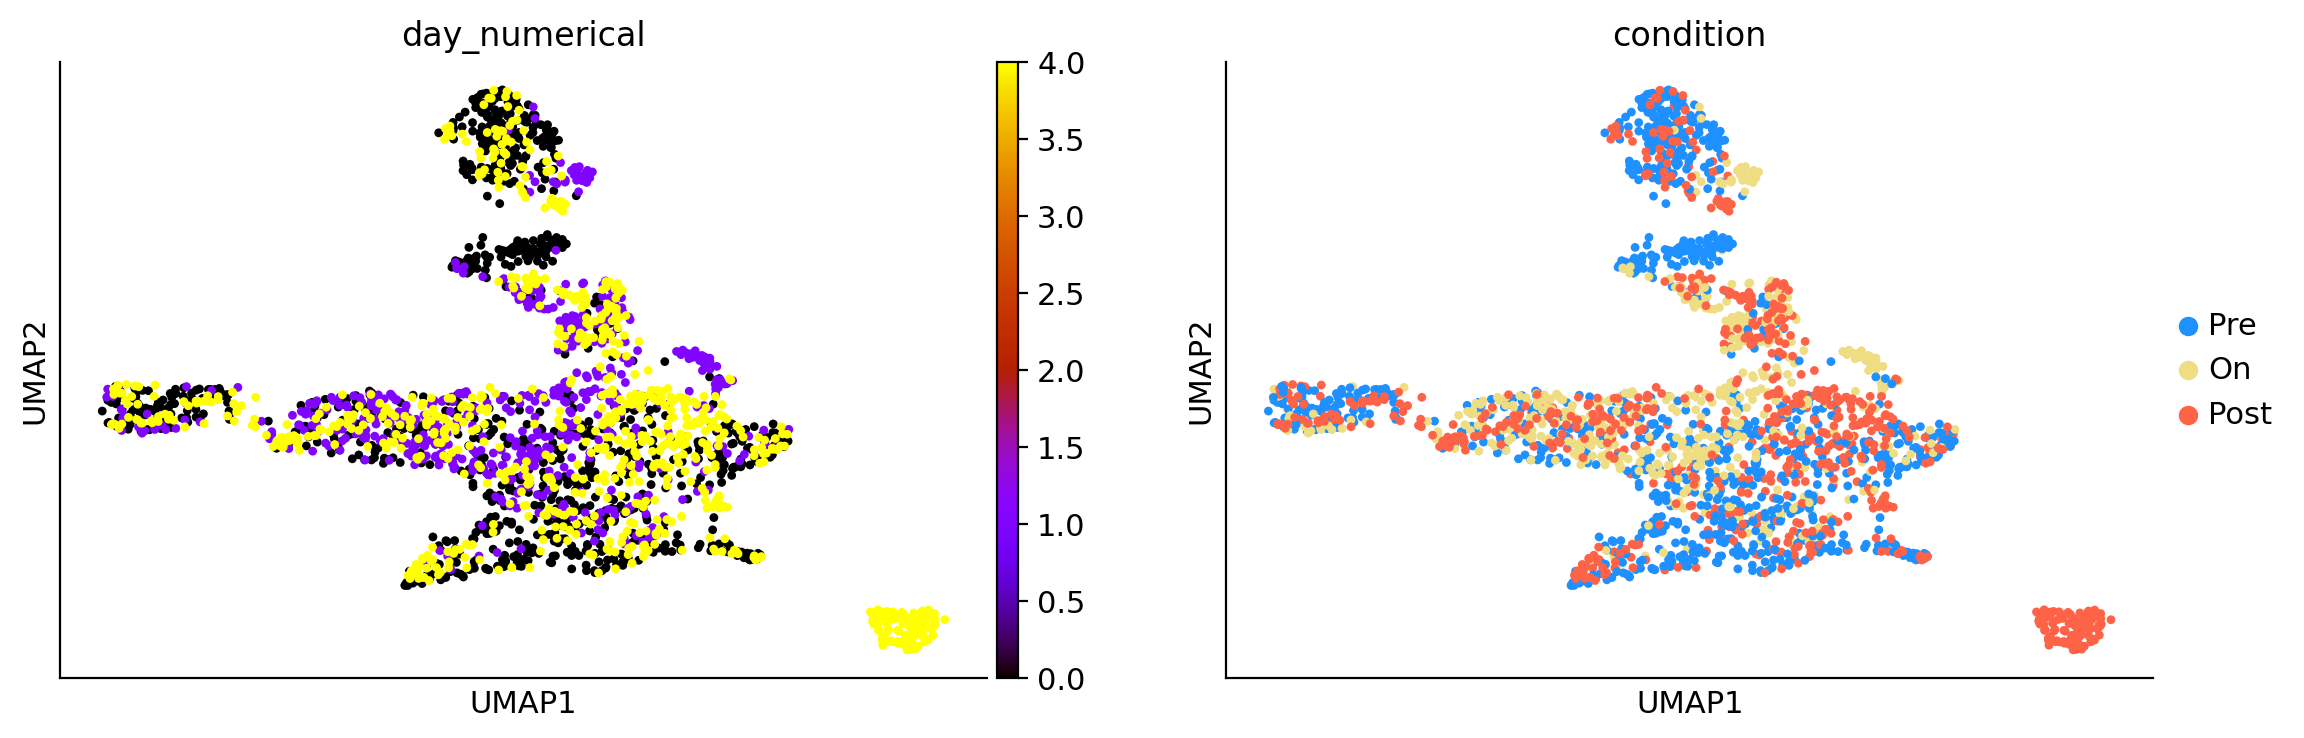

In [12]:
sc.pl.embedding(
    adata,
    basis="umap",
    color=["day_numerical", "condition"],
    color_map="gnuplot",
    size=40
)

In [13]:
tp = TemporalProblem(adata)

In [14]:
tp = tp.score_genes_for_marginals(
    gene_set_proliferation="human", gene_set_apoptosis="human"
)

In [15]:
tp = tp.prepare(time_key="day")

INFO     Computing pca with `n_comps=30` for `xy` using `adata.X`                                                  
INFO     Computing pca with `n_comps=30` for `xy` using `adata.X`                                                  


In [16]:
tp = tp.solve(epsilon=1e-3, tau_a=0.95, scale_cost="mean")

INFO     Solving `2` problems                                                                                      
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(1021, 571)].                                   
INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(571, 814)].                                    


In [17]:
tmk = RealTimeKernel.from_moscot(tp)

In [18]:
tmk.compute_transition_matrix(self_transitions="all", conn_weight=0.2, threshold="auto")

  0%|          | 0/2 [00:00<?, ?time pair/s]

RealTimeKernel[n=2406, threshold='auto', self_transitions='all']

  0%|          | 0/100 [00:00<?, ?sim/s]

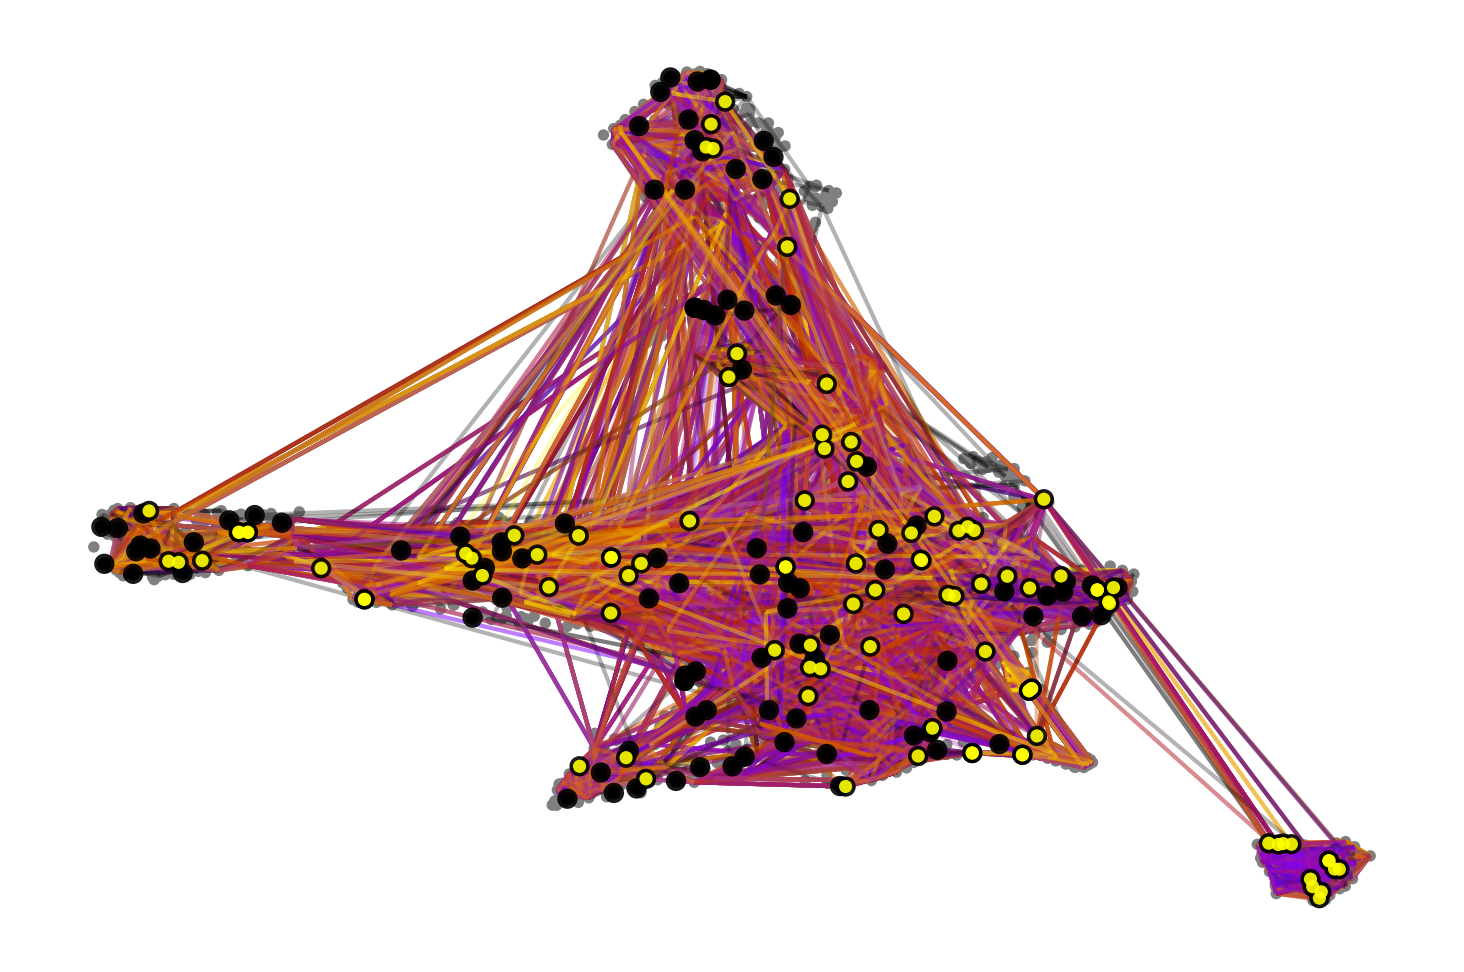

In [19]:
tmk.plot_random_walks(
    max_iter=500,
    start_ixs={"day": 0.0},
    basis="umap",
    seed=0,
    dpi=150,
    size=30,
)

In [20]:
#### trajectory analysis

In [21]:
vrk = 0.7 * vk + 0.3 * tmk

In [22]:
from cellrank.estimators import GPCCA

g = GPCCA(vrk)
print(g)

GPCCA[kernel=(0.7 * VelocityKernel[n=2406] + 0.3 * RealTimeKernel[n=2406]), initial_states=None, terminal_states=None]


/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/utils.py:1396: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/utils.py:1397: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


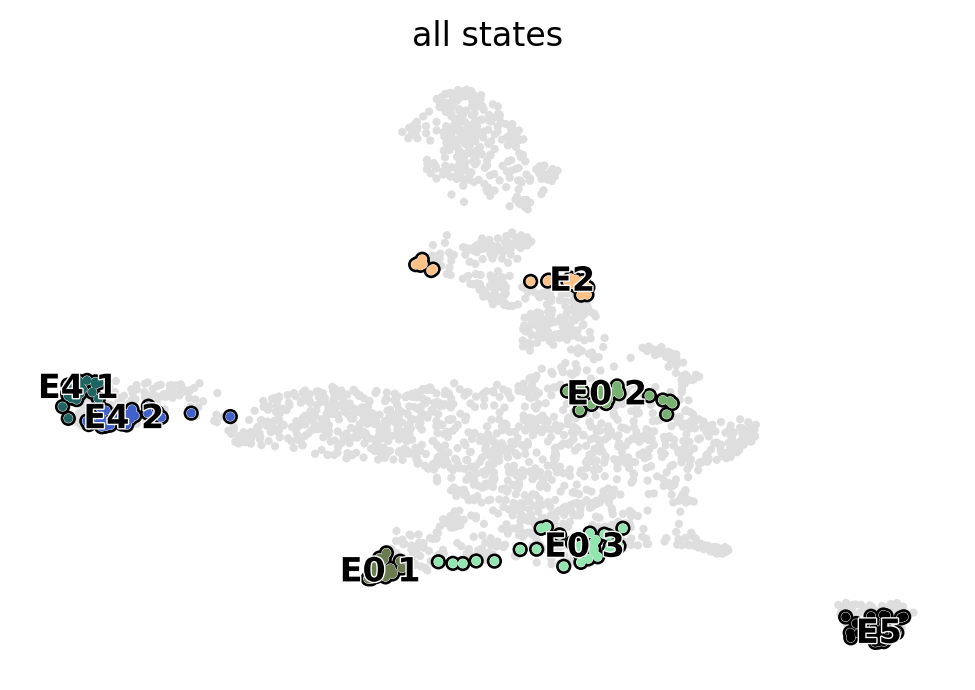

In [23]:
g.fit(n_states=7, cluster_key="Endothelial_clusters")
g.plot_macrostates(which="all")

In [24]:
g.set_initial_states(states=['E0_1'],allow_overlap=True)

GPCCA[kernel=(0.7 * VelocityKernel[n=2406] + 0.3 * RealTimeKernel[n=2406]), initial_states=[np.str_('E0_1')], terminal_states=None]

In [25]:
g.set_terminal_states(states=['E2', 'E4_2', 'E5'],allow_overlap=True)

GPCCA[kernel=(0.7 * VelocityKernel[n=2406] + 0.3 * RealTimeKernel[n=2406]), initial_states=[np.str_('E0_1')], terminal_states=[np.str_('E2'), np.str_('E4_2'), np.str_('E5')]]

Defaulting to `'gmres'` solver.


  0%|          | 0/3 [00:00<?, ?/s]

/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/home/yuseong2/anaconda3/envs/moscr/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


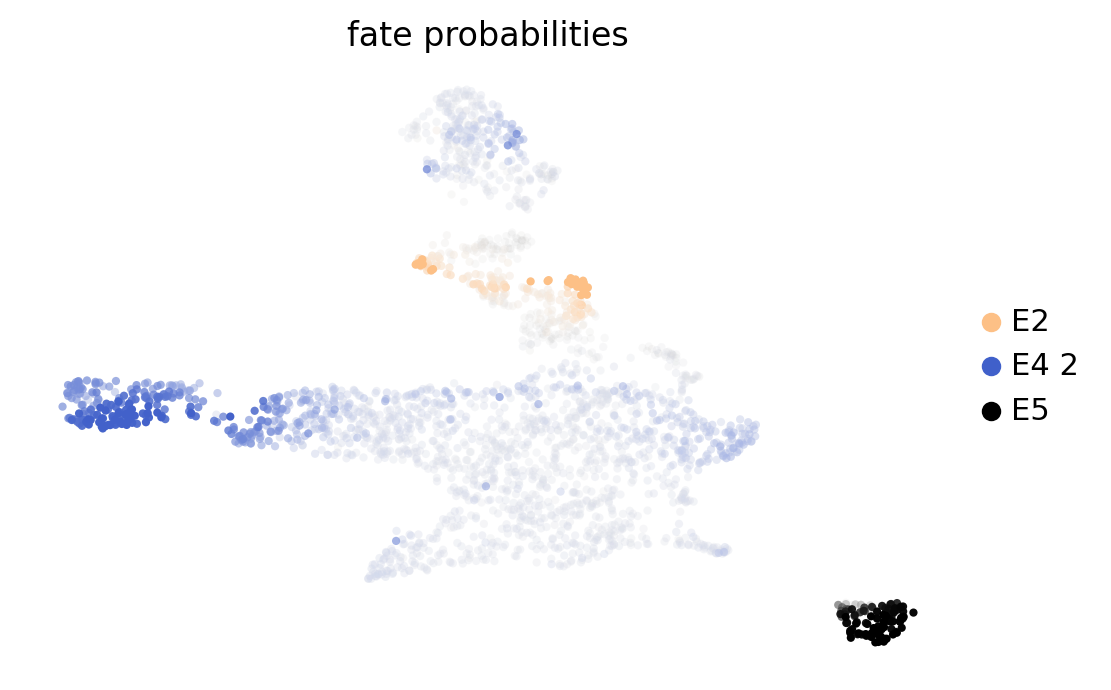

In [26]:
g.compute_fate_probabilities()
g.plot_fate_probabilities(legend_loc="right")

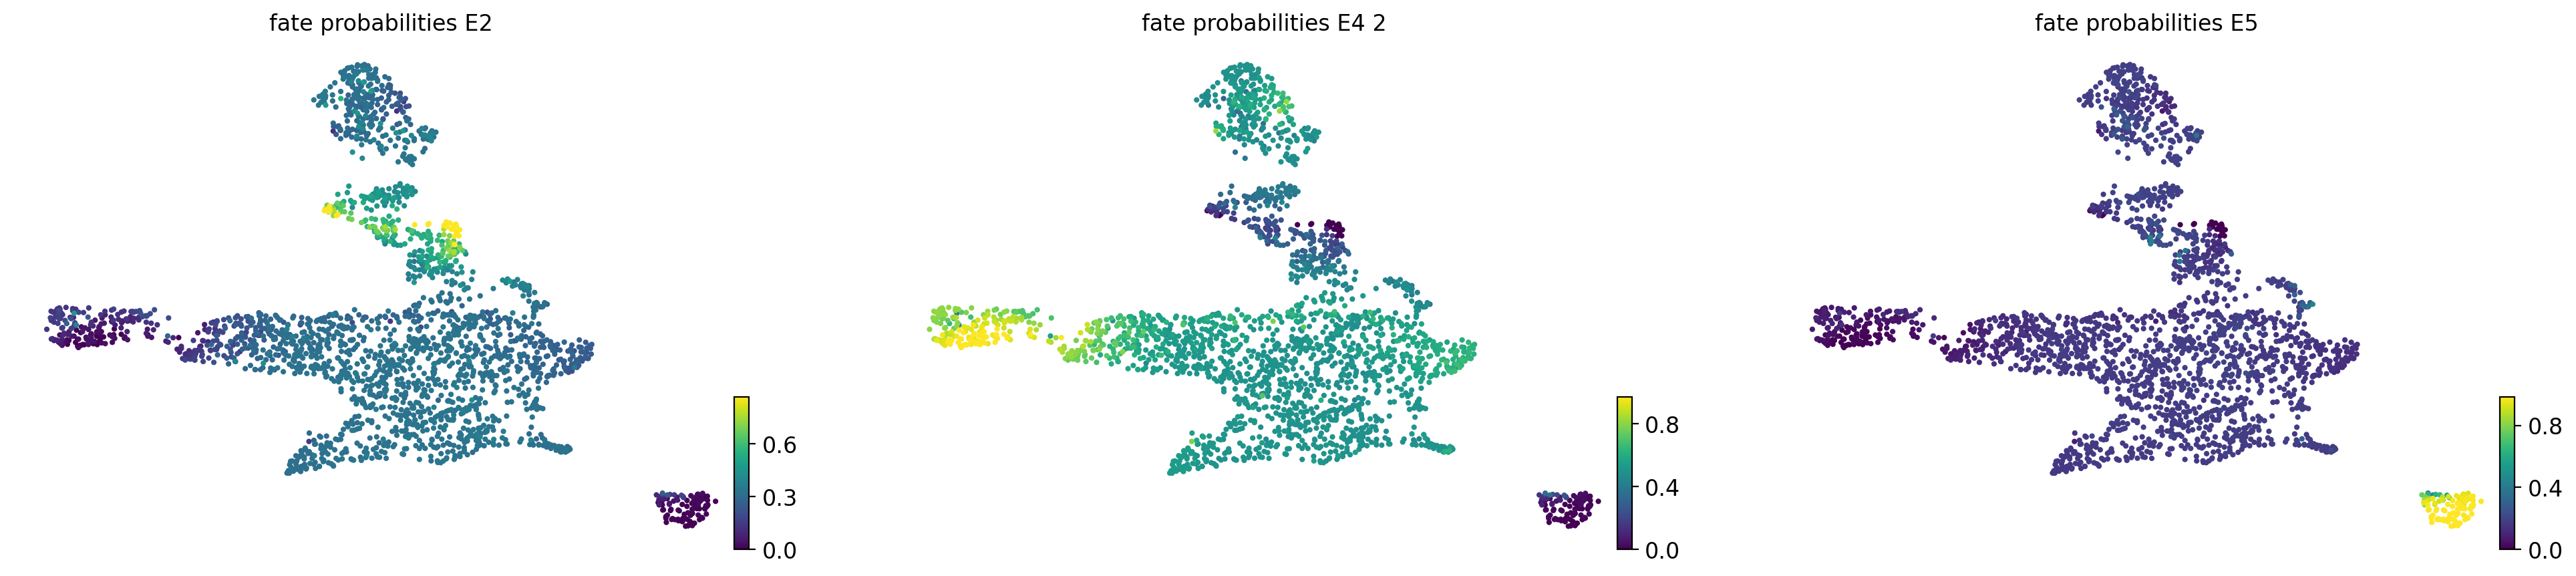

In [27]:
g.plot_fate_probabilities(same_plot=False,  ncols=3, figsize = (8,5))

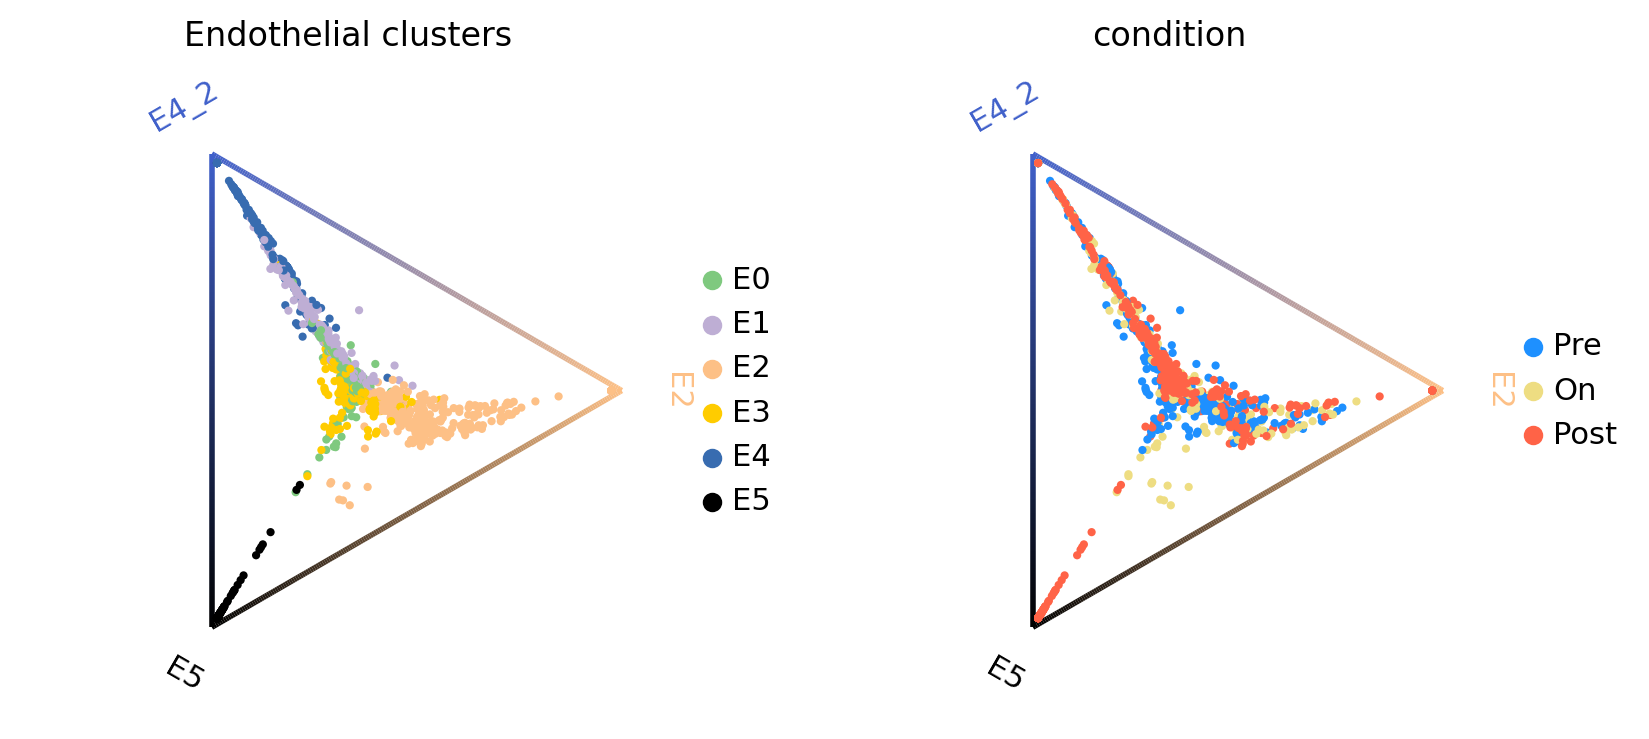

In [28]:
cr.pl.circular_projection(adata, keys=["Endothelial_clusters", "condition"], legend_loc="right")

In [29]:
### latent time for gene trend

In [30]:
initial = g.macrostates[g.macrostates == 'E0_1'].index.tolist()
initial[:5]

['HyPR.HN.01.2.tumor_On_GACCCAGGTCTTGTCC.1',
 'HyPR.HN.02.3_Post_AACTTTCGTGAGGCTA.1',
 'HyPR.HN.02.3_Post_CGGAGTCTCAGTACGT.1',
 'HyPR.HN.03.1_Pre_GCGCCAATCCTTAATC.1',
 'HyPR.HN.03.1_Pre_GGAACTTAGCTTATCG.1']

computing latent time using root_custom as prior
    finished (0:00:02) --> added 
    'latent_time', shared time (adata.obs)


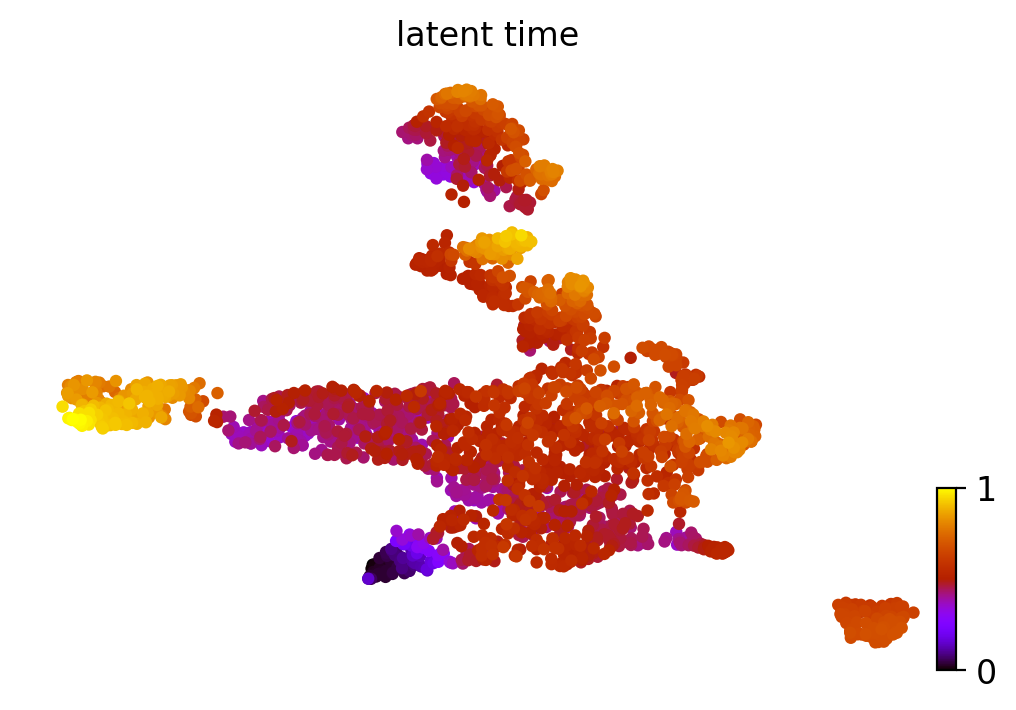

In [31]:
adata.obs['root_custom'] = adata.obs.index.isin(initial).astype(int)
scv.tl.latent_time(adata, root_key = 'root_custom')
scv.pl.scatter(adata, color='latent_time', color_map='gnuplot', size=80)

In [32]:
adata.write_h5ad('data/2f_h_j/patient_endo_cellrank.h5ad')

In [33]:
#### pathway trends

In [34]:
adata = sc.read_h5ad('data/2f_h_j/patient_endo_cellrank.h5ad')

In [35]:
x = adata.to_df()
x.head()

,DDX11L2,MIR1302-2HG,ENSG00000290826,ENSG00000238009,ENSG00000239906,ENSG00000241860,ENSG00000241599,ENSG00000286448,ENSG00000236601,ENSG00000290385,...,ENSG00000268674,ENSG00000276345,ENSG00000277856,ENSG00000275063,ENSG00000273554,ENSG00000277836,ENSG00000278633,ENSG00000276017,ENSG00000278817,ENSG00000277196
HyPR.HN.01.1.tumor_Pre_AACCAACTCTCTATGT.1,-0.020387,0.0,0.0,-0.020387,0.0,-0.070716,0.0,-0.026734,0.0,-0.086288,...,0.0,-0.093197,-0.058417,-0.058925,0.0,-0.020387,0.0,0.0,-0.084264,-0.09008
HyPR.HN.01.1.tumor_Pre_AACTTCTTCGCCTATC.1,-0.020387,0.0,0.0,-0.020387,0.0,-0.070716,0.0,-0.026734,0.0,-0.086288,...,0.0,-0.093197,-0.058417,-0.058925,0.0,-0.020387,0.0,0.0,-0.084264,-0.09008
HyPR.HN.01.1.tumor_Pre_AATGGCTCACCAGCTG.1,-0.020387,0.0,0.0,-0.020387,0.0,-0.070716,0.0,-0.026734,0.0,-0.086288,...,0.0,-0.093197,-0.058417,-0.058925,0.0,-0.020387,0.0,0.0,-0.084264,-0.09008
HyPR.HN.01.1.tumor_Pre_ACAGAAACAAGAGTTA.1,-0.020387,0.0,0.0,-0.020387,0.0,-0.070716,0.0,-0.026734,0.0,-0.086288,...,0.0,-0.093197,-0.058417,-0.058925,0.0,-0.020387,0.0,0.0,-0.084264,-0.09008
HyPR.HN.01.1.tumor_Pre_ACAGGGATCAATCCGA.1,-0.020387,0.0,0.0,-0.020387,0.0,-0.070716,0.0,-0.026734,0.0,-0.086288,...,0.0,-0.093197,-0.058417,-0.058925,0.0,-0.020387,0.0,0.0,-0.084264,-0.09008


In [36]:
score = pd.read_csv('data/2f_h_j/patient_endo_GSVA_scores_+ME_ssgsea_bicor_norm.csv',
                   index_col = 0)
score.head()

,EMT,ECM,SEN_MAYO,CELLULAR.RESPONSE.TO.UV,RESPONSE.TO.UV,EndMT,M3
HyPR.HN.01.1.tumor_Pre_AACCAACTCTCTATGT.1,-0.294992,-0.507833,-0.673809,-0.215079,-0.602581,-0.129561,1.030188
HyPR.HN.01.1.tumor_Pre_AACTTCTTCGCCTATC.1,0.549428,0.178154,0.277335,-0.633802,-0.476470,0.687439,-1.058611
HyPR.HN.01.1.tumor_Pre_AATGGCTCACCAGCTG.1,-0.687306,-0.682431,-0.747108,-0.289328,-0.708648,0.650226,0.436092
HyPR.HN.01.1.tumor_Pre_ACAGAAACAAGAGTTA.1,-0.091663,0.293108,1.159483,1.234073,1.020156,0.057577,-1.739380
HyPR.HN.01.1.tumor_Pre_ACAGGGATCAATCCGA.1,-1.352606,-1.389897,-0.757712,-1.023587,-1.197578,-0.685145,-0.557987


In [37]:
x_score = pd.merge(x, score,left_index = True, right_index=True)
len(x_score), len(x), len(score)

(2406, 2406, 2406)

In [38]:
from scipy.sparse import coo_matrix, csr_matrix
test = ad.AnnData(X=csr_matrix(x_score))

In [39]:
test.obs = adata.obs
test.uns = adata.uns
test.obsm = adata.obsm
test.obsp = adata.obsp

In [40]:
test.var.index = x_score.columns.to_list()

In [41]:
n_comps = 10
dm_res = palantir.utils.run_diffusion_maps(pd.DataFrame(test.obsm['X_pca'][:, :n_comps], index=test.obs_names))

In [42]:
imp_df = palantir.utils.run_magic_imputation(test, dm_res)

In [43]:
from scipy.sparse import issparse
if issparse(imp_df):
    imp = imp_df.toarray()
imp = pd.DataFrame(imp, index=test.obs_names, columns=test.var_names)

In [44]:
# filter to those genes for which we have imputed expression values
mask = np.in1d(test.var_names, imp.columns)
test = test[:, mask].copy()

# add imputed data to an extra layer in AnnData
test.layers["magic_imputed_data"] = imp[test.var_names].loc[test.obs_names]

In [45]:
model = cr.models.GAMR(test)

  0%|          | 0/4 [00:00<?, ?gene/s]

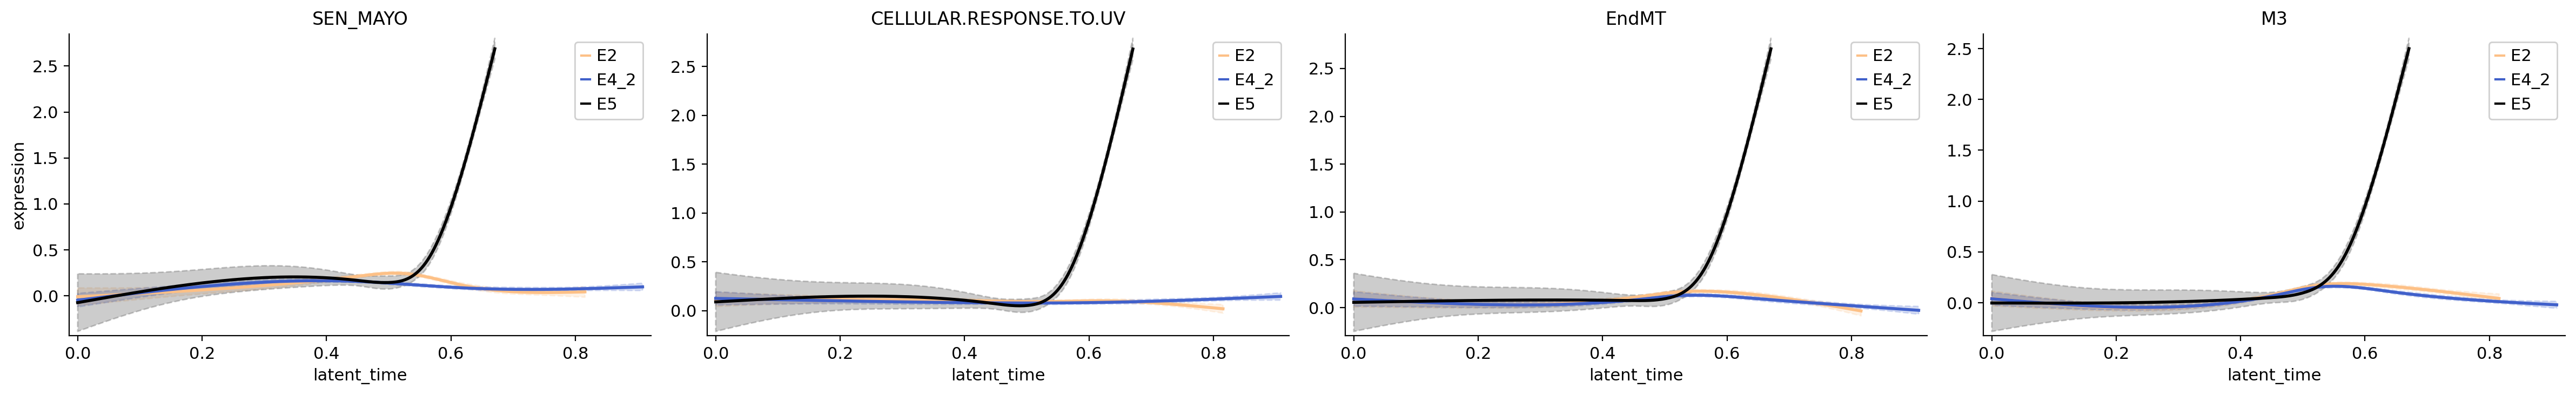

In [46]:
cr.pl.gene_trends(
    test,
    model=model,
    data_key="magic_imputed_data",
    genes=['SEN_MAYO', 'CELLULAR.RESPONSE.TO.UV','EndMT','M3'],
    same_plot=True,
    ncols=4,
    time_key="latent_time",
    hide_cells=True,
    weight_threshold=(1e-3, 1e-3),
)